<a href="https://colab.research.google.com/github/islam-alim/transaction-risk-prediction/blob/main/notebooks/IEEE_fraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup

In [67]:
# 1. Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 2. Подключение Google Drive
from google.colab import drive
drive.mount("/content/drive")

# 3. Путь к проекту
PROJECT_DIR = Path(
    "/content/drive/MyDrive/transaction-risk-prediction"
)

# 4. Путь к датасету
DATA_PATH = PROJECT_DIR / "data/raw/train_transaction.csv"

# 5. Загрузка данных
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Данные успешно загружены!")
    print("Размер:", df.shape)
else:
    print("Ошибка: файл не найден!")
    print(DATA_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Данные успешно загружены!
Размер: (16594, 394)


In [68]:
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [69]:
df['isFraud']

,isFraud
0,0
1,0
2,0
3,0
4,0
...,...
16589,0
16590,0
16591,0
16592,0


In [70]:
df['isFraud'].value_counts()

,count
isFraud,
0,16135
1,459


In [75]:
# Разделим транзакции по сумме
df["is_large"] = df["TransactionAmt"] > 500

# Доля мошенничества в каждой группе
result = df.groupby("is_large")["isFraud"].mean() * 100

print(result)


is_large
False    2.716342
True     4.235727
Name: isFraud, dtype: float64


Исследование дисбаланса классов

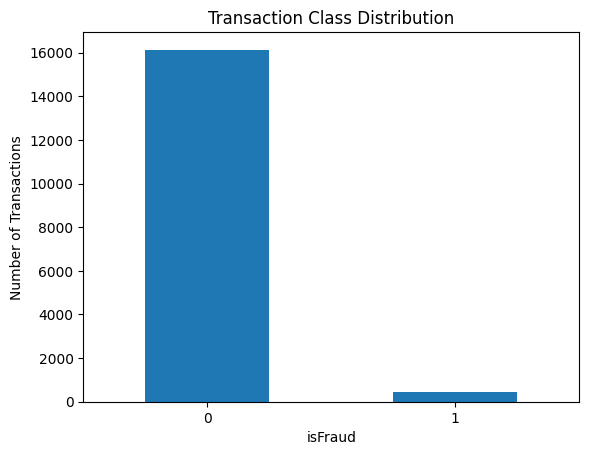

In [76]:
import matplotlib.pyplot as plt

counts = df['isFraud'].value_counts().sort_index()
counts.plot(kind='bar')
plt.title('Transaction Class Distribution')
plt.xlabel('isFraud')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

In [81]:
df['isFraud'].value_counts()

,count
isFraud,
0,16135
1,459


In [83]:
round(df["isFraud"].value_counts(normalize=True) * 100, 2)

,proportion
isFraud,
0,97.23
1,2.77


In [87]:
df['isFraud'].value_counts()[0] / df['isFraud'].value_counts()[1]
# ratio normal / fraud transactions

np.float64(35.152505446623096)

In [94]:

df.groupby("isFraud")["TransactionAmt"].agg(
    ["mean", "median", "min", "max"]
)


,mean,median,min,max
isFraud,,,,
0,126.997237,68.500,1.896,4007.95
1,142.356996,83.742,5.000,2161.00


Распределение сумм транзакций

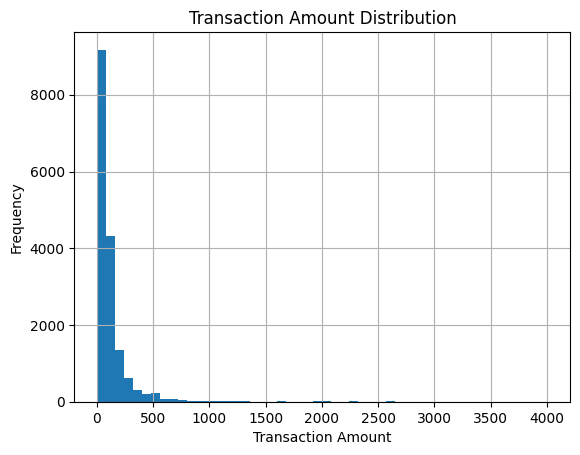

In [95]:
import matplotlib.pyplot as plt

df["TransactionAmt"].hist(bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()
